# Life Expectancy Prediction
### Machine Learning Analysis using Linear Regression, Decision Tree & Random Forest

---
> **Dataset:** WHO Life Expectancy Data  
> **Goal:** Predict life expectancy based on health, economic, and social indicators  
> **Models Used:** Linear Regression · Decision Tree · Random Forest

---
## Section 1 — Data Loading
Import all required libraries and load the dataset.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings


# Load dataset
df = pd.read_csv('Life-Expectancy-Data-Updated.csv')

# Standardise column names: strip spaces, lowercase, replace spaces with underscores
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

print(df.head())

ModuleNotFoundError: No module named 'pandas'

---
## Section 2 — Preprocessing
Handle missing values, encode categorical variables, select features, and scale the data.

In [ ]:
# Fill missing values with column-wise mean (numeric columns only)
df.fillna(df.select_dtypes(include=[np.number]).mean(), inplace=True)

# Encode 'status' column: Developed → 1, Developing → 0
if 'status' in df.columns:
    df['status'] = df['status'].map({'Developed': 1, 'Developing': 0})

# Drop non-numeric identifier column
df.drop(columns=[col for col in ['country'] if col in df.columns], inplace=True)

# Define target variable and feature set
y = df['life_expectancy']
X = df.drop(columns=['life_expectancy'], errors='ignore')

# Keep only numeric features
X = X.select_dtypes(include=[np.number])

# Drop 'year' if present (not a predictive feature)
if 'year' in X.columns:
    X.drop(columns=['year'], inplace=True)

# Compute correlation with target and drop low-correlation features (< 0.05)
corr = X.corr()['life_expectancy'] if 'life_expectancy' in X.columns else df.corr(numeric_only=True)['life_expectancy']
corr = corr.abs()
low_corr = corr[corr < 0.05].index.tolist()
X.drop(columns=low_corr, inplace=True, errors='ignore')

# Standardise features using StandardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Features used: {list(X.columns)}")
print(f"Dataset shape after preprocessing: {X_scaled.shape}")

Features used: ['infant_deaths', 'under_five_deaths', 'adult_mortality', 'alcohol_consumption', 'hepatitis_b', 'measles', 'bmi', 'polio', 'diphtheria', 'incidents_hiv', 'gdp_per_capita', 'thinness_ten_nineteen_years', 'thinness_five_nine_years', 'schooling', 'economy_status_developed', 'economy_status_developing']
Dataset shape after preprocessing: (2864, 16)


---
## Section 3 — Model Training
Split the data and train three regression models: Linear Regression, Decision Tree, and Random Forest.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Train-test split: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# Initialise models
lr = LinearRegression()
dt = DecisionTreeRegressor(max_depth=10, min_samples_split=5, random_state=42)
rf = RandomForestRegressor(n_estimators=100, random_state=42)

# Train all models
lr.fit(X_train, y_train)
dt.fit(X_train, y_train)
rf.fit(X_train, y_train)

print("All models trained successfully.")

All models trained successfully.


---
## Section 4 — Model Evaluation
Compare models using MAE, RMSE, and R² Score.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = {}

for name, model in [('Linear Regression', lr), ('Decision Tree', dt), ('Random Forest', rf)]:
    y_pred = model.predict(X_test)
    results[name] = {
        'MAE':  round(mean_absolute_error(y_test, y_pred), 2),
        'RMSE': round(np.sqrt(mean_squared_error(y_test, y_pred)), 2),
        'R2':   round(r2_score(y_test, y_pred), 4)
    }

# Display results as a formatted DataFrame
results_df = pd.DataFrame(results).T
print(results_df)

                    MAE  RMSE      R2
Linear Regression  1.09  1.36  0.9777
Decision Tree      0.61  0.82  0.9919
Random Forest      0.38  0.52  0.9967


---
## Section 5 — Visualisation
Plot R² scores for all models and display the top 10 most important features from the Random Forest.

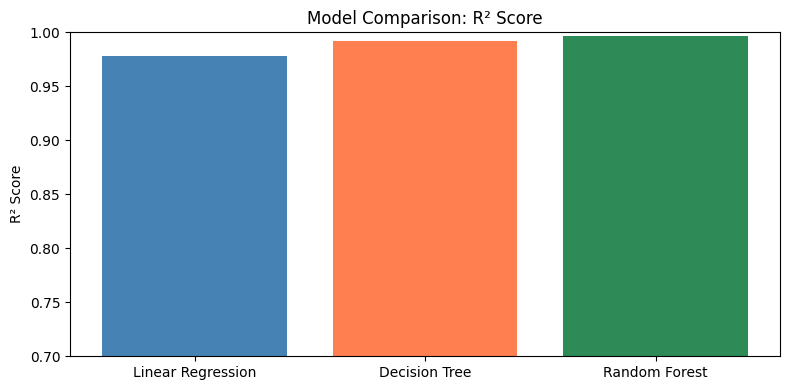

In [ ]:
# --- R² Score Comparison Bar Chart ---
names     = list(results.keys())
r2_scores = [results[n]['R2'] for n in names]

plt.figure(figsize=(8, 4))
plt.bar(names, r2_scores, color=['steelblue', 'coral', 'seagreen'])
plt.ylim(0.7, 1.0)
plt.ylabel('R² Score')
plt.title('Model Comparison: R² Score')
plt.tight_layout()
plt.show()

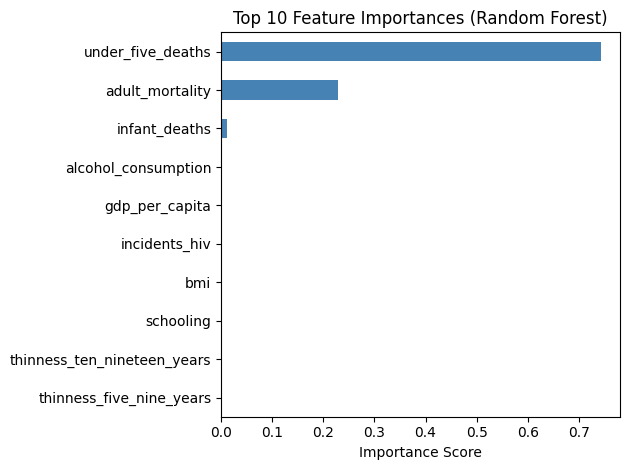

In [ ]:
# --- Top 10 Feature Importances (Random Forest) ---
feat_imp = pd.Series(rf.feature_importances_, index=X.columns)
feat_imp.sort_values().tail(10).plot(kind='barh', color='steelblue')
plt.title('Top 10 Feature Importances (Random Forest)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

<div style="height: 1000px;"></div>

---
## Section 6 — User Input & Prediction
Enter custom values for each feature to get a predicted life expectancy from the Random Forest model.

In [ ]:
user_data = {}

for col in X.columns:
    val = float(input(f"Enter value for {col}: "))
    user_data[col] = val

# Convert to DataFrame, scale, and predict
user_df     = pd.DataFrame([user_data])
user_scaled = scaler.transform(user_df)
prediction  = rf.predict(user_scaled)

print(f"\nPredicted Life Expectancy: {round(prediction[0], 2)} years")

Enter value for infant_deaths: 40
Enter value for under_five_deaths: 55
Enter value for adult_mortality: 150
Enter value for alcohol_consumption: 3.5
Enter value for hepatitis_b: 87
Enter value for measles: 500
Enter value for bmi: 22.5
Enter value for polio: 88
Enter value for diphtheria: 87
Enter value for incidents_hiv: 0.5
Enter value for gdp_per_capita: 1600
Enter value for thinness_ten_nineteen_years: 12
Enter value for thinness_five_nine_years: 12.5
Enter value for schooling: 11.5
Enter value for economy_status_developed: 0
Enter value for economy_status_developing: 1

Predicted Life Expectancy: 68.55 years
